In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
f = np.array([0.0125, 0.005, 0.009])
g = np.array([0.010, 0.006, 0.012])

print(f - g)
print((f-g)**2)

[ 0.0025 -0.001  -0.003 ]
[6.25e-06 1.00e-06 9.00e-06]


In [3]:
ssr = np.sum((f-g)**2)
print(ssr)

1.625000000000001e-05


In [4]:
def Guass(x, mean, sigma):
    return np.exp(-(x - mean)**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))
print(Guass(160,160,7))

0.05699175434306182


In [5]:
f = np.array([.0125, .005, .009, .0258, .0262, .0507, .053, .051, .0455, .0365, .042, .020, .007, .007, .007, .0005])
edges = np.arange(130,210.1, 2.5)
centre = (edges[:-1] + edges[1:]) / 2

data = np.zeros(len(centre))
start = np.searchsorted(edges,160)
data[start:start+len(f)] = f
print(len(edges), len(centre), len(data))

33 32 32


In [6]:
g = Guass(centre, 160, 6)

In [7]:
def histogram(p):
    mean, sigma = p
    g = Guass(centre,mean,sigma)
    ssr = np.sum((data-g)**2)

    plt.bar(centre, data, width=2.5, alpha=0.5, label="Data")
    plt.bar(centre, g,    width=2.5, alpha=0.5, label="Model")
    plt.title(f"SSR = {ssr:.5f}")
    plt.legend(); plt.show()
    return ssr

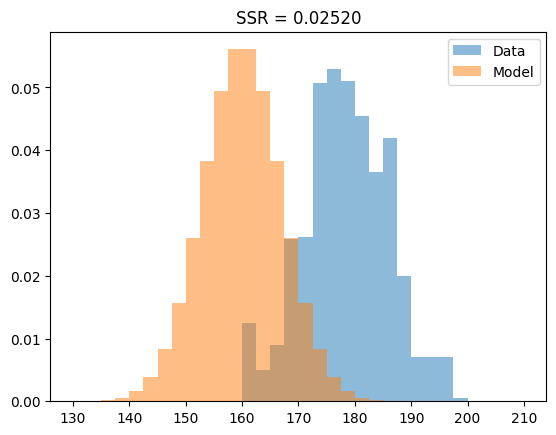

np.float64(0.025198196028812278)

In [8]:
p = [160, 7]
histogram(p)

In [9]:
def ssr(p):
    return np.sum((data- Guass(centre,*p))**2)
mean,sigma,step = 160,7,4
best = ssr([mean,sigma])

while step>1e-4:
    improved = False
    for dm,ds in [(step, 0),(-step,0),(0,step),(0,-step)]:
        s = ssr([mean + dm, sigma + ds])
        if s < best:
            best, mean, sigma, improved = s, mean+dm, sigma+ds, True
    if not improved:
        step /= 2

In [10]:
print(f"μ = {mean:.2f}, σ = {sigma:.2f}, SSR = {best:.6f}")

μ = 178.50, σ = 7.54, SSR = 0.000440


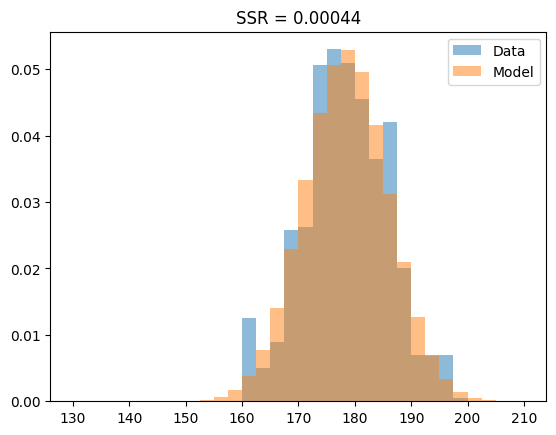

np.float64(0.00043995139282194853)

In [11]:
histogram([mean, sigma])